# What makes an Amazon bestseller? Top-50 lists, 2009–2019

**Questions**
1. Is the list dominated by fiction or non-fiction, and has that changed?
2. How are bestsellers rated, and do ratings differ by genre or over time?
3. What do bestsellers cost, and is price changing?
4. Which books drive engagement (reviews)?
5. Which authors dominate the list?
6. How long do books stay on the list?

**Data:** Amazon's annual Top-50 bestselling books, 2009–2019 (550 rows: title, author, user rating, number of
reviews, price, year, genre), published on Kaggle.

All logic lives in the `bestsellers` package (`src/bestsellers/`) so the notebook stays readable and the same code
powers the report CLI, the SQL checks, the tests and the dashboard.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import pandas as pd
from IPython.display import Image, display
from bestsellers.data import load_raw, clean, to_books
from bestsellers import analysis as A
from bestsellers.sql import run, connect

FIG = ROOT / "reports" / "figures"
pd.set_option("display.max_colwidth", 60)

## 0. Load, validate and clean

In [2]:
raw = load_raw()            # schema + range checks raise if the file is malformed
appearances, log = clean(raw)
books = to_books(appearances)
print(log)
print(f"\n{len(appearances)} list slots -> {len(books)} unique books")

- Exact duplicate rows: 0 (each row is a distinct book-year list slot, so nothing to drop)
- Unified 2 author name variants affecting 9 rows ('George R.R. Martin' -> 'George R. R. Martin', 'J.K. Rowling' -> 'J. K. Rowling')
- Unified 5 rows whose titles differed only in punctuation/case (e.g. 'The 5 Love Languages: The Secret to Love that Lasts')
- Flagged 12 rows with price $0 (free/promotional listings); they are excluded from price statistics but kept everywhere else
- 3 title-year pairs appear twice (different editions of the same book in one year); kept as separate list slots
- NOTE: `reviews` (and mostly `rating`) is a single 2020 snapshot repeated for every year a book appears; it is NOT a per-year measure, so review trends over time are not analysed

550 list slots -> 350 unique books


### Why two tables?
The raw file has **one row per book per year**. A book that stayed on the list for 10 years appears 10 times.
If we average ratings over raw rows (as v1 of this project did), evergreen books are counted up to 10× and
skew every per-book statistic. So:

* **`appearances`** (550 rows): for list-composition and trend questions ("what share of the 2015 list was fiction?")
* **`books`** (350 rows): for book-level questions ("are fiction books rated higher?")

How much does this matter? Here are the v1 numbers next to the corrected ones:

In [3]:
v1 = raw.groupby("Genre")["User Rating"].mean().rename("v1: mean over rows")
v2 = books.groupby("genre", observed=True)["rating"].mean().rename("v2: mean per book")
v2.index = v2.index.astype(str)
pd.concat([v1, v2], axis=1).round(3)

,v1: mean over rows,v2: mean per book
Fiction,4.648,4.616
Non Fiction,4.595,4.603


In [4]:
v1_auth = raw["Author"].value_counts().head(10).rename("v1 'books published'")
A.top_authors(appearances, 10)[["list_appearances", "unique_titles"]].join(v1_auth)

,list_appearances,unique_titles,v1 'books published'
author,,,
Jeff Kinney,12,12,12.0
Rick Riordan,11,10,11.0
Suzanne Collins,11,5,11.0
Gary Chapman,11,2,11.0
American Psychological Association,10,1,10.0
Dr. Seuss,9,2,9.0
Gallup,9,1,9.0
J. K. Rowling,8,8,NaN
Rob Elliott,8,2,8.0


v1 labelled `value_counts()` as *number of books published*, but it actually counts **list appearances**.
Gary Chapman has 11 appearances but only **2** distinct titles, and Jeff Kinney really did place 12 different books.
Name variants (e.g. "J.K. Rowling" vs "J. K. Rowling") also split one author into two in v1.

## 1. Genre mix

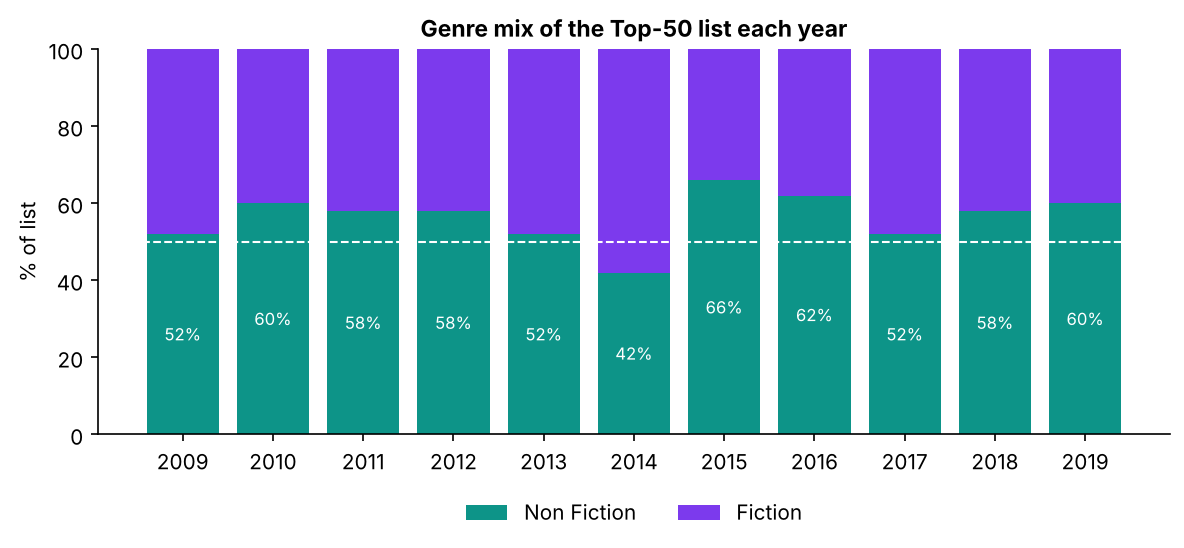

{'fiction_share_overall': 0.43636363636363634,
 'slope_per_year': -0.0032727272727272718,
 'p_value': 0.6236159779989507,
 'min_year': 2015,
 'min_share': 0.34,
 'max_year': 2014,
 'max_share': 0.58}

In [5]:
display(Image(FIG / "genre_mix_by_year.png", width=700))
A.genre_trend_test(appearances)

Non-fiction holds ~56% of slots. 2014 was the only year fiction led (the *Frozen* tie-ins, *The Fault in Our Stars*,
*Gone Girl* and others). A regression of yearly fiction share on year shows **no significant trend** (p ≈ 0.62): the mix
fluctuates but doesn't drift.

## 2. Ratings

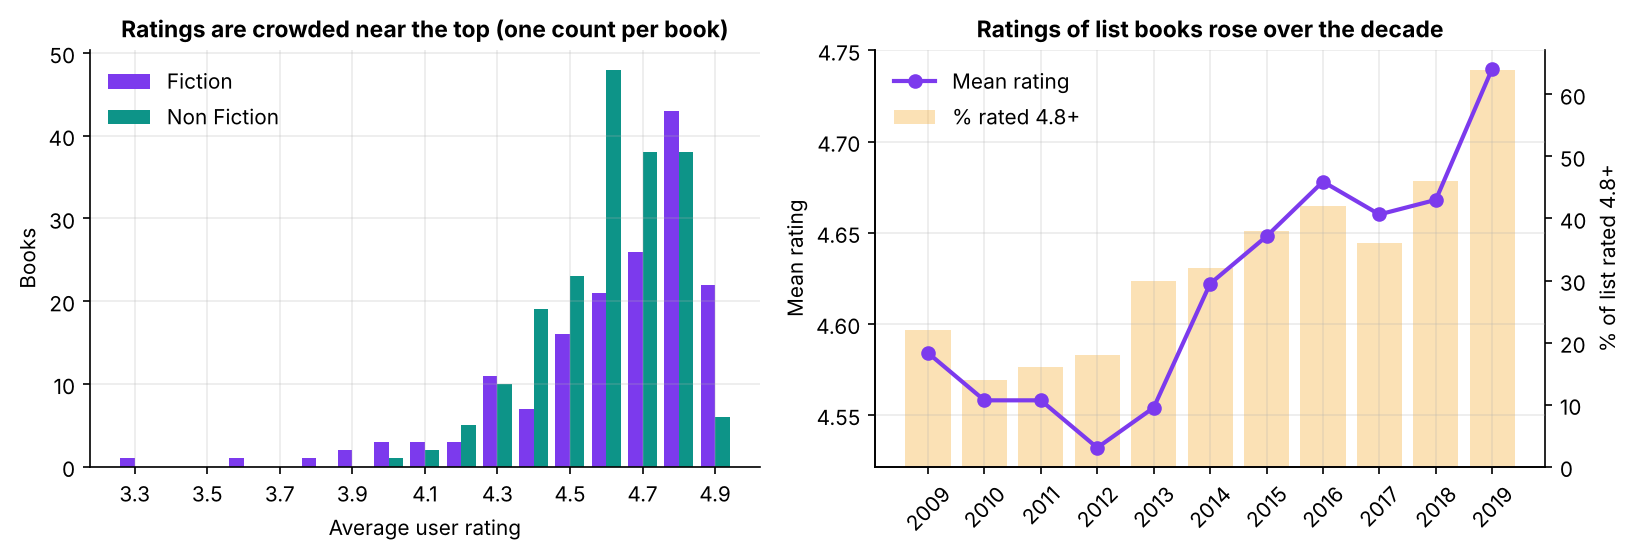

,books,mean,median,std,min,max
genre,,,,,,
Fiction,160,4.616,4.7,0.274,3.3,4.9
Non Fiction,190,4.603,4.6,0.178,4.0,4.9


In [6]:
display(Image(FIG / "ratings.png", width=900))
A.rating_summary_by_genre(books)

In [7]:
pd.Series(A.compare_genres(books, 'rating')).to_frame('Fiction vs Non Fiction (per book)')

,Fiction vs Non Fiction (per book)
column,rating
fiction_median,4.7
nonfiction_median,4.6
fiction_mean,4.615625
nonfiction_mean,4.602594
n_fiction,160
n_nonfiction,190
u_statistic,17421.5
p_value,0.016899
rank_biserial,-0.146151


* Ratings are **compressed**: ~80% of books score ≥ 4.5. A rating is weak evidence of *which* bestseller is better.
* Fiction has a slightly higher median (4.7 vs 4.6, Mann-Whitney p ≈ 0.02) but a small effect size, and it also has
  every rating below 4.0, so its spread is wider.
* I used **Mann-Whitney U** rather than a t-test because ratings are bounded and heavily left-skewed.
* Mean rating rose from 4.58 to 4.74 over the decade. Because all ratings were captured in a single 2020 snapshot,
  this means *later lists contain higher-rated books*, not that readers grew more generous. Survivorship
  and recency could both play a role.

In [8]:
A.rating_by_year(appearances).T

year,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
mean,4.584,4.558,4.558,4.532,4.554,4.622,4.648,4.678,4.66,4.668,4.74
median,4.600,4.600,4.600,4.600,4.600,4.650,4.700,4.700,4.70,4.700,4.80
share_4_8_plus,0.220,0.140,0.160,0.180,0.300,0.320,0.380,0.420,0.36,0.460,0.64


## 3. Prices

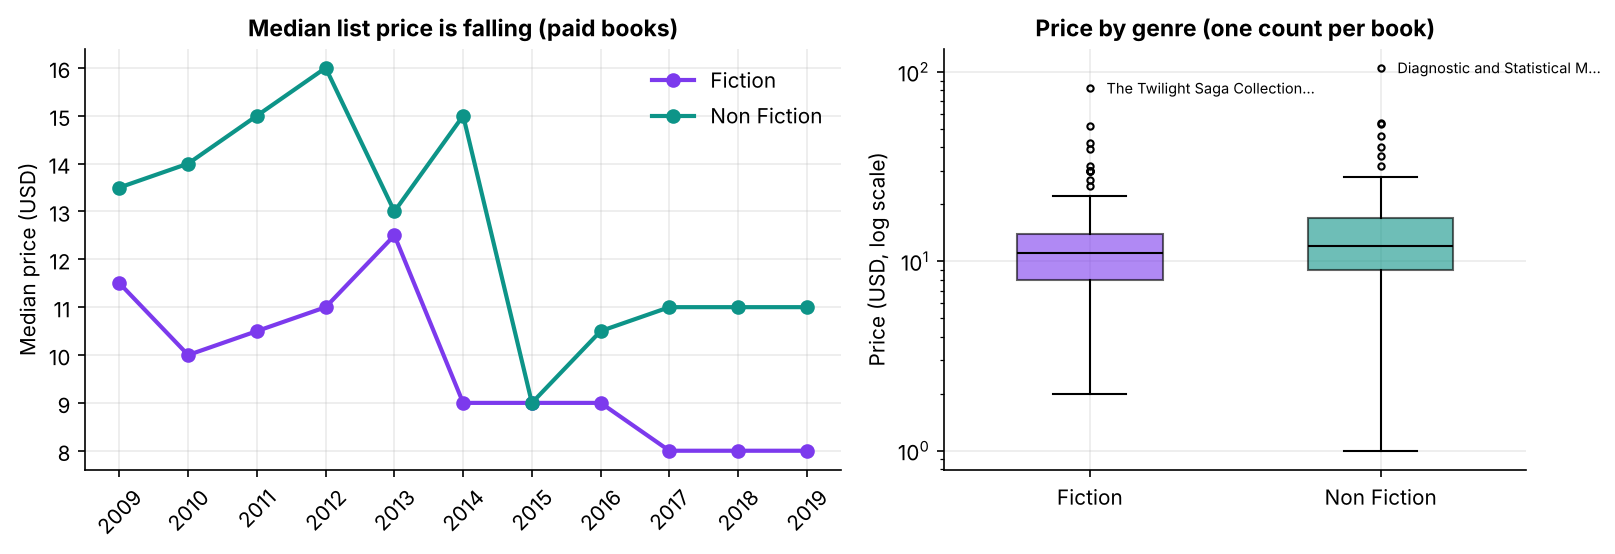

spearman_rho        -2.195390e-01
p_value              2.700940e-07
median_first_year    1.200000e+01
median_last_year     1.000000e+01
dtype: float64

In [9]:
display(Image(FIG / "prices.png", width=900))
pd.Series(A.price_trend_test(appearances))

In [10]:
A.price_outliers(books).head(8)

,title,author,genre,price
0,"Diagnostic and Statistical Manual of Mental Disorders, 5...",American Psychiatric Association,Non Fiction,105.0
1,The Twilight Saga Collection,Stephenie Meyer,Fiction,82.0
2,Hamilton: The Revolution,Lin-Manuel Miranda,Non Fiction,54.0
3,The Book of Basketball: The NBA According to The Sports Guy,Bill Simmons,Non Fiction,53.0
4,Harry Potter Paperback Box Set (Books 1-7),J. K. Rowling,Fiction,52.0
5,Publication Manual of the American Psychological Associa...,American Psychological Association,Non Fiction,46.0
6,Watchmen,Alan Moore,Fiction,42.0
7,The Official SAT Study Guide,The College Board,Non Fiction,40.0


* Median paid price fell from **$12 (2009) to $10 (2019)**. Fiction fell further, from ~$11.5 to $8, possibly
  reflecting cheaper paperback/e-book editions being listed.
* The 12 free ($0) list slots are excluded from price statistics instead of dragging averages down.
* High-price outliers are reference books (DSM-5, APA manual, SAT guides) and box sets, not typical novels.

## 4. Engagement: reviews

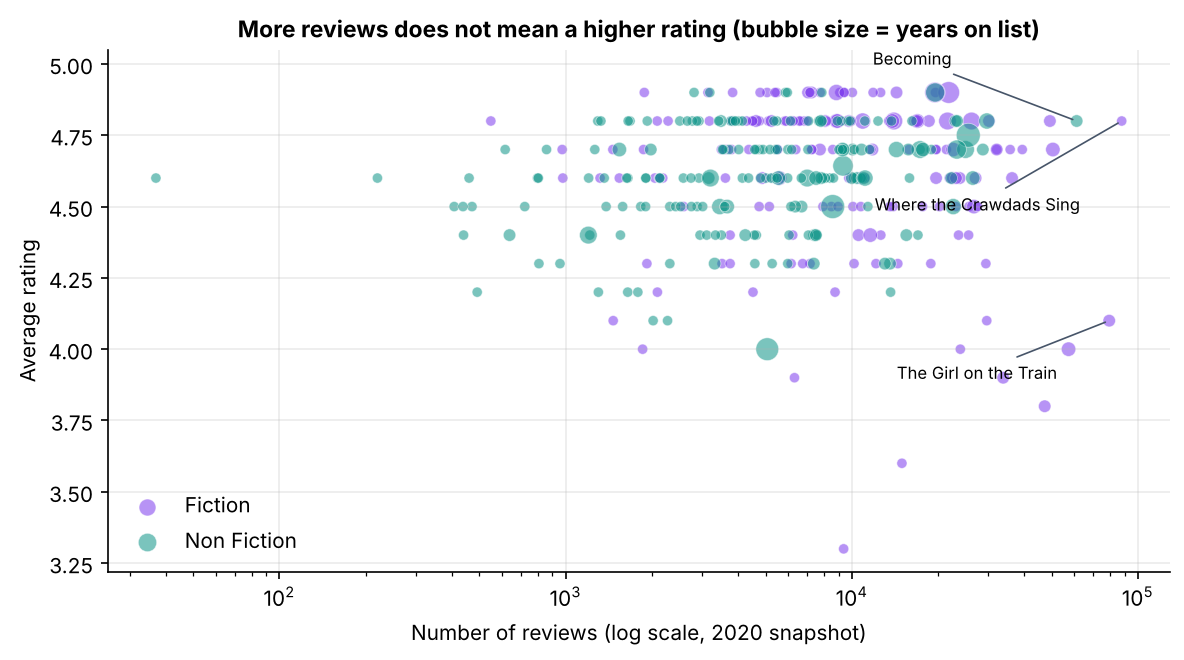

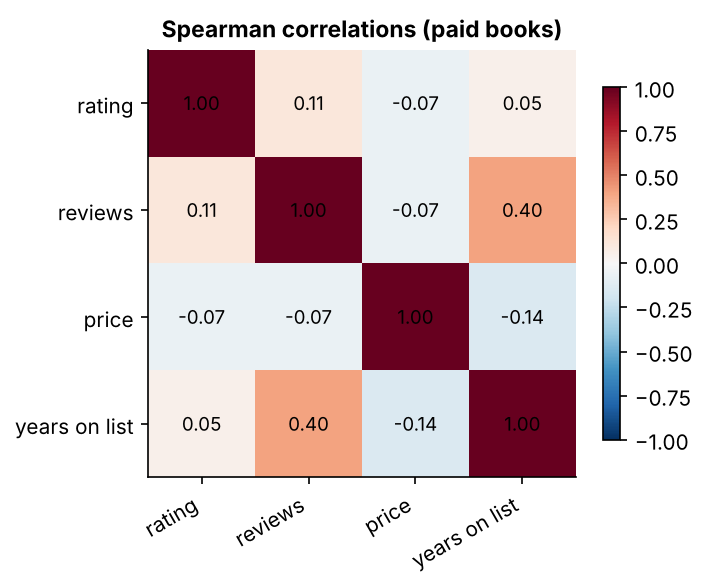

In [11]:
display(Image(FIG / "reviews_vs_rating.png", width=800))
display(Image(FIG / "correlations.png", width=420))

In [12]:
A.most_reviewed(books, 8)

,title,author,genre,reviews,rating,years_on_list
0,Where the Crawdads Sing,Delia Owens,Fiction,87841,4.8,1
1,The Girl on the Train,Paula Hawkins,Fiction,79446,4.1,2
2,Becoming,Michelle Obama,Non Fiction,61133,4.8,2
3,Gone Girl,Gillian Flynn,Fiction,57271,4.0,3
4,The Fault in Our Stars,John Green,Fiction,50482,4.7,3
5,The Nightingale: A Novel,Kristin Hannah,Fiction,49288,4.8,2
6,Fifty Shades of Grey: Book One of the Fifty Shades Trilo...,E L James,Fiction,47265,3.8,2
7,The Martian,Andy Weir,Fiction,39459,4.7,1


* Fiction books get **~75% more reviews** at the median (8.8k vs 5.0k, p < 0.001, medium effect).
* Reviews correlate with **years on the list** (ρ ≈ 0.40) but barely with rating (ρ ≈ 0.11). Popular ≠ best-loved:
  *Fifty Shades of Grey* and *Gone Girl* have huge review counts and some of the lowest ratings.

## 5. Authors

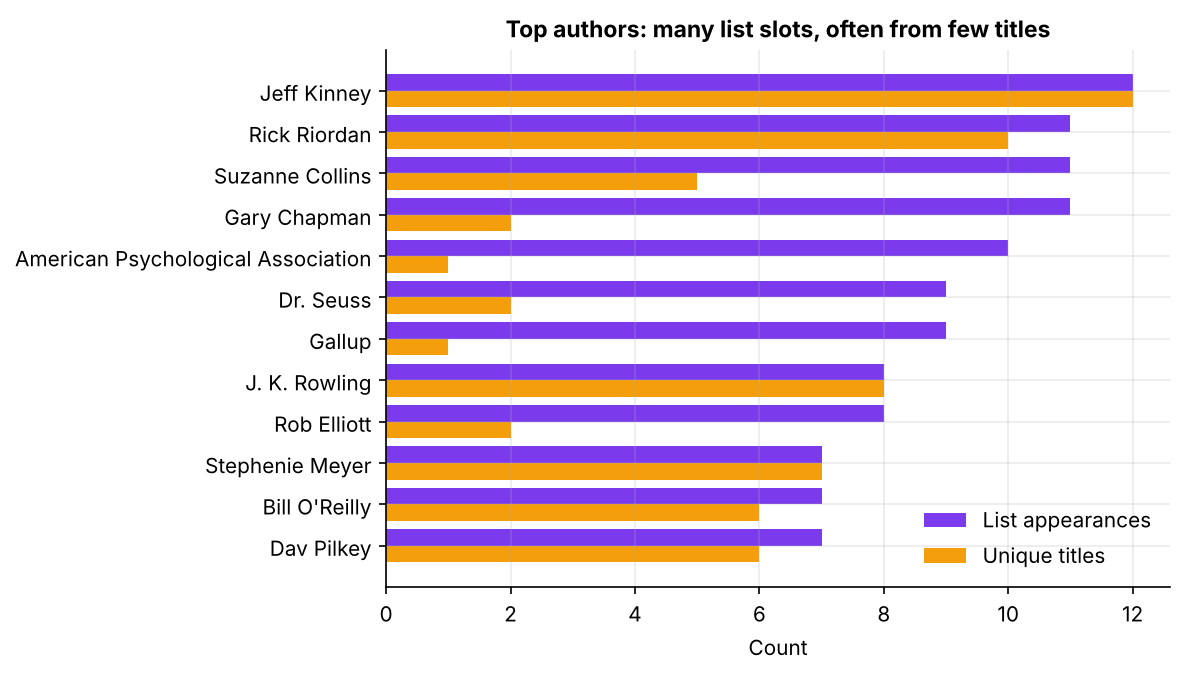

unique_authors                  246.000000
top_10_share_of_slots             0.174545
one_appearance_authors_share      0.528455
dtype: float64

In [13]:
display(Image(FIG / "top_authors.png", width=700))
pd.Series(A.author_concentration(appearances))

A long tail: 53% of authors appear exactly once, and the top 10 hold only 17% of slots. Two routes to dominance:
**franchises** (Jeff Kinney, Rick Riordan, Suzanne Collins: many titles) and **evergreens** (Gary Chapman, APA,
Gallup: one or two titles that never leave).

## 6. Longevity

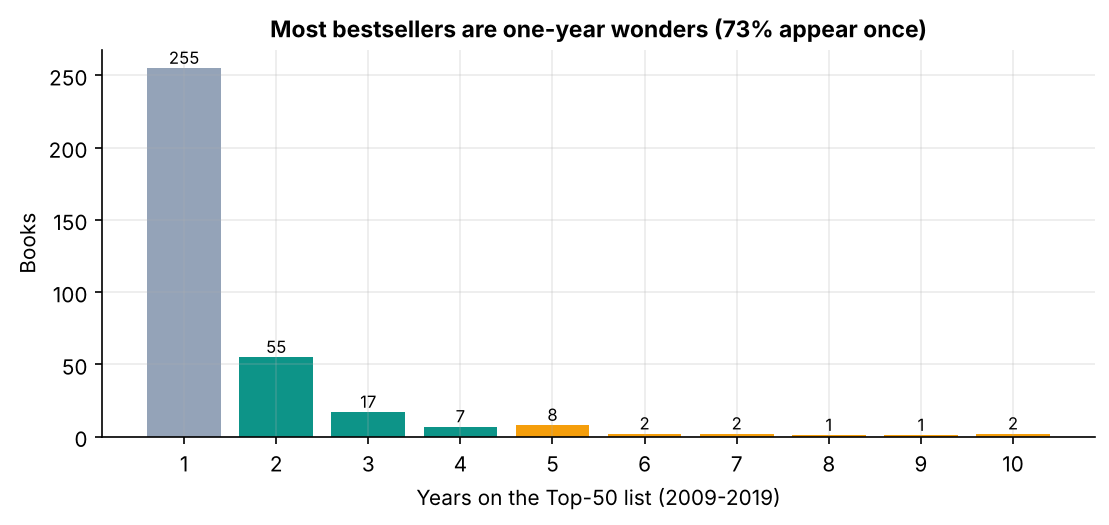

,title,author,genre,years_on_list,first_year,last_year,rating
0,The 5 Love Languages: The Secret to Love That Lasts,Gary Chapman,Non Fiction,10,2010,2019,4.750000
1,Publication Manual of the American Psychological Associa...,American Psychological Association,Non Fiction,10,2009,2018,4.500000
2,StrengthsFinder 2.0,Gallup,Non Fiction,9,2009,2017,4.000000
3,"Oh, the Places You'll Go!",Dr. Seuss,Fiction,8,2012,2019,4.900000
4,The Very Hungry Caterpillar,Eric Carle,Fiction,7,2013,2019,4.900000
5,The 7 Habits of Highly Effective People: Powerful Lesson...,Stephen R. Covey,Non Fiction,7,2009,2017,4.642857
6,The Four Agreements: A Practical Guide to Personal Freed...,Don Miguel Ruiz,Non Fiction,6,2013,2019,4.700000
7,Jesus Calling: Enjoying Peace in His Presence (with Scri...,Sarah Young,Non Fiction,6,2011,2016,4.900000
8,To Kill a Mockingbird,Harper Lee,Fiction,5,2013,2019,4.800000
9,How to Win Friends & Influence People,Dale Carnegie,Non Fiction,5,2014,2018,4.700000


In [14]:
display(Image(FIG / "longevity.png", width=700))
A.evergreens(books, 10)

In [15]:
A.longevity_by_genre(books)

,books,mean_years,share_one_year,share_evergreen
genre,,,,
Fiction,160,1.488,0.725,0.031
Non Fiction,190,1.626,0.732,0.058


73% of bestsellers appear in only one year. Non-fiction is twice as likely to become an evergreen (5+ years): self-help and reference books sell steadily for years.

## 7. The same answers in SQL
The key queries are re-implemented in `sql/queries.sql` and run with DuckDB. The test suite checks that SQL and pandas agree.

In [16]:
con = connect(appearances, books)
run("newcomers_per_year", con)

,year,new_titles,titles_on_list,newcomer_share
0,2009,50,50,1.000
1,2010,40,50,0.800
2,2011,31,49,0.633
3,2012,28,50,0.560
4,2013,33,50,0.660
5,2014,27,48,0.563
6,2015,29,50,0.580
7,2016,28,50,0.560
8,2017,27,50,0.540
9,2018,31,50,0.620


In [17]:
run("evergreens", con)

,title,author,genre,years_on_list,longevity_rank
0,Publication Manual of the American Psychological Associa...,American Psychological Association,Non Fiction,10,1
1,The 5 Love Languages: The Secret to Love That Lasts,Gary Chapman,Non Fiction,10,1
2,StrengthsFinder 2.0,Gallup,Non Fiction,9,2
3,"Oh, the Places You'll Go!",Dr. Seuss,Fiction,8,3


## Conclusions
1. **Non-fiction rules the list (56%)**, steadily, with no decade-long trend.
2. **Ratings don't separate bestsellers**: 80% are ≥ 4.5, so use reviews or longevity as a popularity signal instead.
3. **Prices fell** ~17% at the median, most sharply for fiction.
4. **Fiction drives engagement**; non-fiction drives longevity.
5. **73% are one-year wonders**: staying power comes from franchises or evergreen self-help/reference titles.

**Limitations:** no within-year rank, ratings/reviews are a 2020 snapshot, and genre is a coarse two-way label.
**Next steps:** enrich with Goodreads/Open Library metadata (page count, sub-genre, publication date) and model
which features predict a book staying on the list for more than one year.